# Fermionic models: loss and protection of equilibrium information

This notebook covers Sec. IV of the paper and produces Figs. 1 and 2 of the main text and
Figs. S1 and S2 of Appendix B (`fermionic_local_sensitivity`, `fermionic_finite_error`,
`fermionic_dark_comparison`, `speedlimit_sensitivity`).

The fermionic models are the one place in the paper where *both* sides of the inequality
are known exactly: the mean-force Gibbs (MFG) state, which gives the bound, and the reduced
dynamics, which gives the thermalization time it bounds. They are therefore the test of the
bound itself, and the setting in which one can see what makes it tight or loose.

The notebook reads the stored output of the three computation scripts and rebuilds the
figures; it recomputes a few quantities from more elementary ones as a check, but it does not
rerun the sweeps. Section 7 says how to do that.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
from scipy.special import digamma
from scipy.optimize import brentq

import planckian as pk
import plotstyle as ps
from planckian import read_csv, select, column, sort_by
from plotstyle import (EPS_COLOR, BLUES, BLUE_MAIN, OP_COLOR, LAMBDA_COLOR, GREY_REF,
                       LW_REF, figure, grid, title, shared_legend, eps_label)

DATA = Path('data/fermionic')
FIGS = Path('figures'); FIGS.mkdir(exist_ok=True)
ps.setup()

XLIM = (1e-2, 1e3)          # the common range of beta g^2 in every fermionic figure
LWD, MS_D = 1.1, 2.8        # thinner lines than the lattice figure: these panels overlay many curves


def save(fig, name):
    fig.savefig(FIGS / f'{name}.pdf')
    return fig


def symlog(ax, lin, top):
    """Log axes with a linear strip below ``lin``, so that exact zeros stay visible."""
    ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=lin, linscale=.35)
    ax.set_ylim(-lin / 10, top); ax.set_xlim(*XLIM)
    ax.axhspan(-lin / 10, lin, color='.94', zorder=0, lw=0)

## 1. The models

$N$ fermionic levels $d_n$ couple to one common reservoir [Eq. (26)],

$$H_S=\sum_{n=1}^{N}\epsilon_n\,d_n^\dagger d_n,\qquad
  H_B=\sum_k\Omega_k\,b_k^\dagger b_k,\qquad
  V=g\sum_{n,k}\bigl(t_k\,d_n^\dagger b_k+t_k^*\,b_k^\dagger d_n\bigr),$$

with a Lorentzian reservoir [Eq. (27)],
$\mathcal J(\Omega)=2\pi\sum_k|t_k|^2\delta(\Omega-\Omega_k)=\Lambda^2/(\Lambda^2+\Omega^2)$, so
that $g^2\mathcal J(\Omega)$ is the level broadening and $g^2$, the hybridization energy at the
Fermi level, measures the coupling. Energies are measured from the chemical potential of the
reservoir.

$H_{\rm tot}$ is quadratic and conserves particle number. For a factorized initial state with a
Gaussian, number-conserving $\rho_S(0)$, the reduced state stays Gaussian and is fixed by the
one-particle density matrix $C_{mn}(t)=\mathrm{Tr}[\rho_S(t)\,d_n^\dagger d_m]$, whose
relaxation is governed by [Eq. (28)]

$$\Gamma=-\frac{i}{\hbar}\,h-\frac{g^2}{2\hbar}\,\bm u\bm u^{\rm T},\qquad
  \bm u=(1,\dots,1)^{\rm T},\qquad h=\mathrm{diag}(\epsilon_1,\dots,\epsilon_N),$$

and whose stationary value is the MFG correlation matrix [Eq. (29)]

$$C^{\rm th}=\frac12\,\mathbb I-\frac{1}{2\pi i}
  \left[\psi\!\left(\frac12\,\mathbb I-\frac{\beta\hbar}{2\pi}\Gamma\right)-\mathrm{h.c.}\right],$$

with $\psi$ the digamma function. Both the MFG state and the reduced dynamics are therefore
available in closed form at **arbitrary** coupling, with no weak-coupling or Markovian
approximation. The collective term $\bm u\bm u^{\rm T}$ is what creates the bright and dark
modes. Two instances are used:

* **resonant-level model (RLM)**, $N=1$. Parity conservation leaves the level shift
  $\kappa=n_d$ as the only admissible perturbation — a projector, so $\|n_d\|=1$ — and the MFG
  state is the single occupation $p_{\rm th}$.
* **double quantum dot (DQD)**, $N=2$, with $\bar\epsilon=(\epsilon_1+\epsilon_2)/2$ and detuning
  $\Delta=\epsilon_1-\epsilon_2$. In the bright/dark basis $d_\pm=(d_1\pm d_2)/\sqrt2$ [Eq. (33)],

  $$H_S=\bar\epsilon\,(n_++n_-)+\tfrac{\Delta}{2}\bigl(d_+^\dagger d_-+\text{h.c.}\bigr),\qquad
    V=\sqrt2\,g\sum_k\bigl(t_k\,d_+^\dagger b_k+\text{h.c.}\bigr),$$

  so the reservoir couples to the bright mode only and $[n_-,V]=0$. The dark mode relaxes only
  through the detuning that mixes it with the bright one. This is the structure that protects
  equilibrium information at strong coupling.

Units everywhere: $\hbar=\beta=1$, energies in $k_BT$, times in $\tau_{\rm Pl}=\hbar\beta$. For
a quadratic $\kappa=\sum_{mn}k_{mn}d_m^\dagger d_n$ the Fock-space spectral seminorm is
$\|\kappa\|=\sum_i|\lambda_i(k)|$, so $\|N_S\|=2$ and $\|n_\pm\|=1$; the normalized common shift
is therefore $N_S/2$.

## 2. What the bound needs

**Finite accuracy.** On a ball $\mathcal B_\delta(\bar H_S)=\{H_S:\|H_S-\bar H_S\|\le\delta\}$,
Theorem 1 bounds the thermalization time $\tau_{\delta,\varepsilon}$ of Eq. (7) by
$\tau_{\delta,\varepsilon}\geq\tau_{\rm Pl}\chi$, with [Eq. (8)]

$$\chi(\bar H_S,\delta,\varepsilon)=\max_{\substack{H^{(1)},H^{(2)}\in\mathcal B_\delta\\
  H^{(1)}\neq H^{(2)}}}
  \left[\frac{2D\bigl(\tilde\omega^{(1)},\tilde\omega^{(2)}\bigr)-4\varepsilon}
       {\beta\,\|H^{(1)}-H^{(2)}\|}\right]_+,$$

where $D$ is the Bures angle. Only the equilibrium targets enter.

**A one-parameter family.** The finite-error tests fix a direction instead of the whole ball
[Eq. (30)],

$$H_S(x)=\bar H_S+x\,\hat\kappa,\qquad\|\hat\kappa\|=1,\qquad|x|\leq\delta,$$

so that $\|H_S(x_1)-H_S(x_2)\|=|x_1-x_2|$. Theorem 1 compares Hamiltonians pairwise, so it
applies to the family and gives $\tau_\varepsilon\geq\tau_{\rm Pl}\chi_\delta$ with the maximum
restricted to pairs of members. Both $\tau_{\delta,\varepsilon}$ and the bound for the whole
ball can only be larger, since the family is contained in it.

**Locally exact limit.** Shrinking the ball with $\varepsilon/(\beta\delta)\to0$ gives
$\tau\geq\tau_{\rm Pl}\widetilde\chi$ with [Eq. (10)]

$$\widetilde\chi=\max_{\|\kappa\|=1}\frac{\sqrt{\mathcal F^{\rm th}_\kappa}}{\beta},$$

the quantum Fisher information of the MFG family. Its variational form [Eq. (16)],
$\mathcal F^{\rm th}_\kappa=\max_A\xi_{A\kappa}^2/\mathrm{Var}_{\tilde\omega}(A)$, is what makes
it computable: $\xi_{A\kappa}=-\partial_\delta\langle A\rangle_{\tilde\omega}$ is a static
susceptibility of a system observable.

**Ceiling.** The last inequality of Eq. (17) gives $2D\leq\tfrac{\beta}{2}\|H^{(1)}-H^{(2)}\|$,
and two members of $\mathcal B_\delta$ differ by at most $2\delta$, so

$$\chi\leq\Bigl[\tfrac12-\frac{2\varepsilon}{\beta\delta}\Bigr]_+,$$

and a nontrivial bound needs $\varepsilon<\beta\delta/4$. Every model below uses
$\delta=2\pi k_BT$ and quotes $\varepsilon$ in units of $\varepsilon_{\max}=\pi/4$, the largest
accuracy for which $\chi_\delta$ can be nonzero at all, since Bures angles never exceed $\pi/2$.
The value $\beta\delta=2\pi$ is chosen so that for a weakly coupled level at resonance the
thermal occupation runs from nearly 1 at $x=-\delta$ to nearly 0 at $x=\delta$, making the
extreme targets nearly orthogonal; in the other regimes the same fixed $\delta$ asks whether the
equilibrium state still resolves Hamiltonians on that scale.

## 3. Locally exact constraints (Fig. 1)

`data/fermionic/local_sensitivity/local_sensitivity.csv` holds, for each coupling
$\gamma=\beta g^2$ on a log grid from $10^{-2}$ to $10^{3}$:

| column | meaning |
|---|---|
| `model` | `rlm` or `dqd` |
| `E`, `mean` | $\beta\epsilon$ (RLM) or $\beta\bar\epsilon$ (DQD) |
| `direction` | the perturbation $\kappa$: `level`, `common_shift` ($N_S$), `dot1` ($n_1$), `detuning`, `bright` ($n_+$), `dark` ($n_-$), `tunnelling`, and `optimum_single_mode`, the constrained maximum over single-mode occupations $n_v$ |
| `F` | $\mathcal F^{\rm th}_\kappa$, the QFI of the MFG family |
| `chi_tilde` | $\sqrt{\mathcal F^{\rm th}_\kappa}/\beta$, each perturbation normalized to $\|\kappa\|=1$ |
| `resp_*` | $\xi_{A\kappa}^2/\mathrm{Var}_{\tilde\omega}(A)$ for the readouts $A=N_S,\,n_1,\,n_-$ |

The ratio `resp_A / F` is therefore the fraction of the available information that a *single*
observable $A$ recovers, by the variational form of the QFI. It is 1 when $A$ is the symmetric
logarithmic derivative of the family.

In [2]:
R = read_csv(DATA / 'local_sensitivity' / 'local_sensitivity.csv')
print(f'{len(R)} rows; couplings: {len({r["gamma"] for r in R})} values '
      f'from {min(r["gamma"] for r in R):g} to {max(r["gamma"] for r in R):g}')
print('perturbations:', sorted({r['direction'] for r in R}))

714 rows; couplings: 42 values from 0.01 to 1000
perturbations: ['bright', 'common_shift', 'dark', 'detuning', 'dot1', 'level', 'optimum_single_mode', 'tunnelling']


### Check: the RLM value against its closed form

For the RLM the MFG family stays diagonal and $\kappa=n_d$ is a projector onto one of two
levels, so measuring the occupation recovers the full QFI, the first inequality of Eq. (17) is
tight, and Eq. (23) holds with [Eq. (32)]

$$\widetilde\chi=\frac{|\partial_\epsilon p_{\rm th}|}{\beta\sqrt{p_{\rm th}(1-p_{\rm th})}},
  \qquad
  p_{\rm th}=\frac12-\frac1\pi\,\mathrm{Im}\,\psi\!\left(\frac12+\frac{\beta}{2\pi}
  \Bigl(\frac{g^2}{2}+i\epsilon\Bigr)\right),$$

with $\psi$ the digamma function. The occupation and its derivative are elementary, so this is
an independent route to the first panel of the figure: evaluate $p_{\rm th}$ from the formula,
differentiate it numerically, and compare with the stored `chi_tilde`.

In [3]:
def p_rlm(eps, g2):
    """Wide-band MFG occupation of the resonant level, Eq. (21)."""
    return 0.5 - np.imag(digamma(0.5 + (g2 / 2 + 1j * np.asarray(eps)) / (2 * np.pi))) / np.pi


worst = 0.0
for E in (0.0, 1.0, 3.0):
    rr = sort_by(select(R, model='rlm', E=E), 'gamma')
    g2, stored = column(rr, 'gamma', 'chi_tilde')
    h = 1e-5
    closed = pk.chi_tilde_two_level(p_rlm(E, g2), (p_rlm(E + h, g2) - p_rlm(E - h, g2)) / (2 * h))
    worst = max(worst, np.abs(closed - stored).max())
    print(f'beta*eps = {E:g}:  max |closed form - stored| = {np.abs(closed - stored).max():.2e}')
print(f'\nworst deviation over all RLM rows: {worst:.2e}')

# the two analytic limits quoted in Sec. IV B
print('\nlimits:  weak coupling  chi -> sech(beta eps / 2)/2      strong coupling  chi -> 4/(pi beta g^2)')
for E in (0.0, 1.0, 3.0):
    rr = sort_by(select(R, model='rlm', E=E), 'gamma')
    g2, stored = column(rr, 'gamma', 'chi_tilde')
    weak, strong = 0.5 / np.cosh(E / 2), 4 / (np.pi * g2[-1])
    print(f'  beta*eps = {E:g}:  chi(g^2={g2[0]:g}) = {stored[0]:.5f} vs {weak:.5f}    '
          f'chi(g^2={g2[-1]:g}) = {stored[-1]:.3e} vs {strong:.3e}  '
          f'(ratio {stored[-1] / strong:.4f})')

beta*eps = 0:  max |closed form - stored| = 8.14e-12
beta*eps = 1:  max |closed form - stored| = 1.24e-11
beta*eps = 3:  max |closed form - stored| = 2.53e-11

worst deviation over all RLM rows: 2.53e-11

limits:  weak coupling  chi -> sech(beta eps / 2)/2      strong coupling  chi -> 4/(pi beta g^2)
  beta*eps = 0:  chi(g^2=0.01) = 0.49865 vs 0.50000    chi(g^2=1000) = 1.273e-03 vs 1.273e-03  (ratio 1.0000)
  beta*eps = 1:  chi(g^2=0.01) = 0.44229 vs 0.44341    chi(g^2=1000) = 1.273e-03 vs 1.273e-03  (ratio 1.0000)
  beta*eps = 3:  chi(g^2=0.01) = 0.21190 vs 0.21255    chi(g^2=1000) = 1.273e-03 vs 1.273e-03  (ratio 1.0000)


### The figure

Panel (a) is the RLM at three level energies, with the strong-coupling asymptote
$4/(\pi\beta g^2)$: the level is broadened over $g^2$, its occupation is pinned at $1/2$ and all
equilibrium information about $\epsilon$ is lost. The surviving constraint,
$\tau\geq4\hbar/(\pi g^2)$, is temperature-independent and comparable to the relaxation time
$\hbar/g^2$ — the non-Planckian regime of the criterion. At the other end, $\beta\epsilon=0$ and
weak coupling give $\widetilde\chi\to1/2$, the ceiling of Eq. (21).

Panel (b) is the DQD. Since the extreme points of $\|\kappa\|\leq1$ are, up to sign, the
single-mode occupations $n_v=d_v^\dagger d_v$, convexity of $\sqrt{\mathcal F^{\rm th}_\kappa}$
puts the optimum at one of them, and only the mode $v$ has to be optimized (thick grey). It
stays finite at every coupling and converges to the dark mode, which gives [Eq. (34)]

$$\tau\geq\tau_{\rm Pl}\sqrt{f_\beta(\bar\epsilon)\bigl[1-f_\beta(\bar\epsilon)\bigr]},$$

a Planckian bound independent of the coupling, while the normalized common shift $N_S/2$ keeps
half of it. Panel (c) shows which readout carries that information.

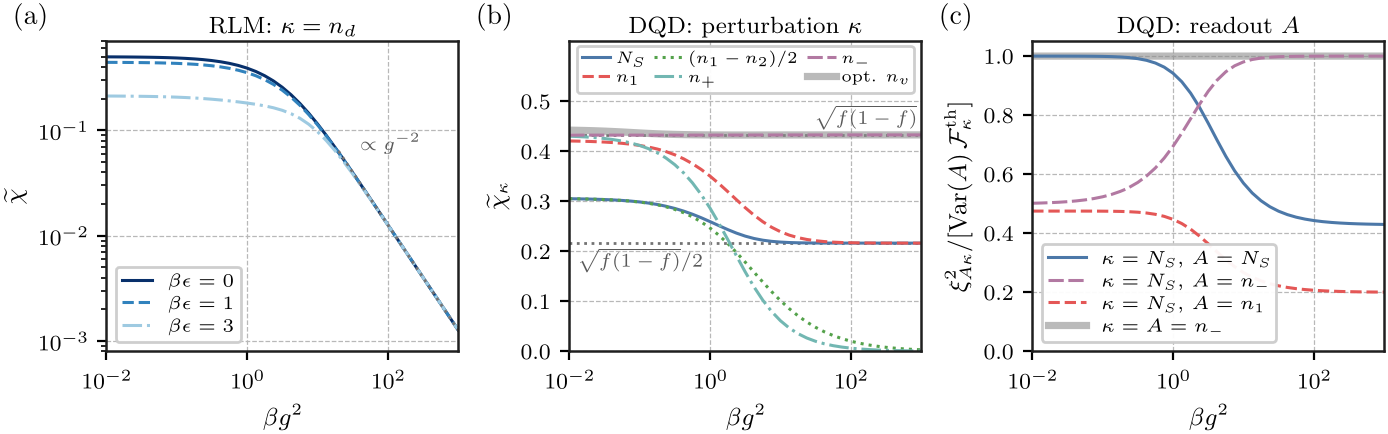

In [4]:
DIRECTION_STYLE = {
    'common_shift': ('-', r'$N_S$'),
    'dot1': ('--', r'$n_1$'),
    'detuning': (':', r'$(n_1-n_2)/2$'),
    'bright': ('-.', r'$n_+$'),
    'dark': ((0, (5, 1.5)), r'$n_-$'),
}
OPT = dict(color='0.55', lw=2.6, alpha=0.6)      # thick grey: optimum over all perturbations

fig, ax = figure('row3')

# (a) RLM, three level energies
for E, c, ls in [(0., BLUES[6], '-'), (1., BLUE_MAIN, '--'), (3., BLUES[1], '-.')]:
    rr = sort_by(select(R, model='rlm', E=E), 'gamma')
    ax[0].loglog(*column(rr, 'gamma', 'chi_tilde'), ls=ls, color=c, lw=LWD,
                 label=fr'$\beta\epsilon={E:g}$')
g = np.logspace(1.3, 3, 10)
ax[0].loglog(g, 1.27 / g, color=GREY_REF, lw=LW_REF, ls=':')
ax[0].text(40, 6.5e-2, r'$\propto g^{-2}$', fontsize=7, color='.35')
ax[0].set(xlabel=r'$\beta g^2$', ylabel=r'$\widetilde\chi$', ylim=(8e-4, .7))
ax[0].legend(loc='lower left', **ps.LEG)
title(ax[0], '(a)', r'RLM: $\kappa=n_d$')

# (b) DQD perturbations
m = 1.1
for d, (ls, lab) in DIRECTION_STYLE.items():
    rr = sort_by(select(R, model='dqd', mean=m, direction=d), 'gamma')
    ax[1].semilogx(*column(rr, 'gamma', 'chi_tilde'), ls=ls, color=OP_COLOR[d], lw=LWD, label=lab)
rr = sort_by(select(R, model='dqd', mean=m, direction='optimum_single_mode'), 'gamma')
ax[1].semilogx(*column(rr, 'gamma', 'chi_tilde'), zorder=1, label=r'opt. $n_v$', **OPT)
f = 1 / (1 + np.exp(m)); q = f * (1 - f)
for y in (np.sqrt(q), np.sqrt(q) / 2):
    ax[1].axhline(y, color=GREY_REF, lw=LW_REF, ls=':', zorder=0)
ax[1].text(30, np.sqrt(q) + .022, r'$\sqrt{f(1-f)}$', fontsize=7, color='.35')
ax[1].text(1.3e-2, np.sqrt(q) / 2 - .012, r'$\sqrt{f(1-f)}/2$', fontsize=7, color='.35', va='top')
ax[1].set(xlabel=r'$\beta g^2$', ylabel=r'$\widetilde\chi_\kappa$', ylim=(0, .62),
          yticks=[0, .1, .2, .3, .4, .5])
ax[1].legend(loc='upper center', ncol=3, fontsize=6.0, columnspacing=0.6, handletextpad=0.35,
             handlelength=1.7, borderpad=0.3, labelspacing=0.2, borderaxespad=0.25)
title(ax[1], '(b)', r'DQD: perturbation $\kappa$')


# (c) DQD readouts: colour = readout operator A
def frac(direction, readout):
    rr = sort_by(select(R, model='dqd', mean=m, direction=direction), 'gamma')
    gam, F = column(rr, 'gamma', 'F')
    return gam, column(rr, 'resp_' + readout) / F


for d, a, op, lab in [('common_shift', 'N', 'common_shift', r'$\kappa=N_S$, $A=N_S$'),
                      ('common_shift', 'dark', 'dark', r'$\kappa=N_S$, $A=n_-$'),
                      ('common_shift', 'n1', 'dot1', r'$\kappa=N_S$, $A=n_1$')]:
    ax[2].semilogx(*frac(d, a), ls=DIRECTION_STYLE[op][0], color=OP_COLOR[op], lw=LWD, label=lab)
ax[2].semilogx(*frac('dark', 'self'), label=r'$\kappa=A=n_-$', zorder=1, **OPT)
ax[2].set(xlabel=r'$\beta g^2$',
          ylabel=r'$\xi_{A\kappa}^2/[\mathrm{Var}(A)\,\mathcal{F}^{\rm th}_\kappa]$', ylim=(0, 1.05))
ax[2].legend(loc='lower left', **{**ps.LEG, 'handlelength': 2.0})
title(ax[2], '(c)', r'DQD: readout $A$')

for a in ax:
    grid(a); a.set_xlim(*XLIM)
save(fig, 'fermionic_local_sensitivity');

## 4. Thermalization times at finite accuracy (Fig. 2)

Now both sides of the inequality. Three one-parameter families are fixed once and only $g^2$
varies along a sweep:

| family | $\hat\kappa$ | $H_S(x)$ | preparation |
|---|---|---|---|
| `rlm` | $n_d$ | $x\,n_d$ | $p(0)=1/2$ |
| `dqd_common` | $N_S/2$ | $\mathrm{diag}(1.2,1.0)\,k_BT+x\,N_S/2$, $\beta\Delta=0.2$ | $(n_1,n_2)=(1,0)$ |
| `dqd_dark` | $n_-$ | $\mathrm{diag}(1.2,1.0)\,k_BT+x\,n_-$, $\beta\Delta=0.2$ | $(n_1,n_2)=(1,0)$ |

all with $|\beta x|\leq\delta=2\pi$ and all three generators of unit seminorm. The measured
quantity is the time at which the *whole* family is simultaneously within $\varepsilon$ of its
targets [Eq. (31)],

$$\tau_\varepsilon=\min\Bigl\{t\geq0:\ \max_{|x|\leq\delta}
  D\bigl(\rho_S(t,x),\tilde\omega_x\bigr)\leq\varepsilon\Bigr\},$$

evaluated on 21 equally spaced members plus the pair that maximizes $\chi_\delta$, each on a
time grid resolving its own oscillation frequencies, with the crossing times refined by
`brentq`. $\chi_\delta$ itself is maximized on a dense pair grid and refined by a constrained
Nelder–Mead search, so the optimal pair is free to move inside the fixed ball as $g^2$ changes.

`sweep.csv` has one row per (`family`, `gamma`, `eps_fraction`) with `chi`, the optimal pair
`x1`, `x2`, the time `tau`, the sustained time `tau_sustained`, and `slowest_rate`.

In [5]:
S = read_csv(DATA / 'families' / 'sweep.csv')
cfg = json.loads((DATA / 'families' / 'config.json').read_text())
print(cfg['units'])
for k, v in cfg['families'].items():
    print(f'  {k:11s} {v}')

tau, chi, taus = column(S, 'tau', 'chi', 'tau_sustained')
eps = column(S, 'epsilon'); dx = np.abs(column(S, 'x1') - column(S, 'x2'))
print(f'\n{len(S)} rows')
print(f'violations of tau_eps >= tau_Pl chi_delta : {int((tau < chi - 1e-12).sum())}')
print(f'violations of the ceiling 1/2 - 2 eps/(beta delta): '
      f'{int((chi > 0.5 - 2 * eps / cfg["delta"] + 1e-12).sum())}')
print(f'rows where a member re-enters after tau_eps  : {int((taus > tau + 1e-12).sum())}')
print(f'largest tightness tau_Pl chi_delta / tau_eps : {np.nanmax(chi[tau > 0] / tau[tau > 0]):.3f}')

hbar=beta=1; gamma=g^2 (wide-band hybridization); energies in k_BT, times in tau_Pl
  rlm         H(x)=x n_d, |x|<=delta, p(0)=1/2
  dqd_common  h(x)=diag(1.2,1.0)+x*N_S/2, |x|<=delta, (n1,n2)=(1,0)
  dqd_dark    h(x)=diag(1.2,1.0)+x*n_-, n_-=(1-X)/2, |x|<=delta, (n1,n2)=(1,0)

665 rows
violations of tau_eps >= tau_Pl chi_delta : 0
violations of the ceiling 1/2 - 2 eps/(beta delta): 0
rows where a member re-enters after tau_eps  : 0
largest tightness tau_Pl chi_delta / tau_eps : 0.259


The bound holds on every row, as it must, and no member leaves the $\varepsilon$-ball again
after $\tau_\varepsilon$, so $\tau_\varepsilon$ is also the sustained time. The tightness is
another matter: at best the bound captures about a quarter of the true time, and for the DQD
families far less. That is expected — it is a necessary condition built from equilibrium data
only — and the interesting question is not how tight it is but whether it stays Planckian.

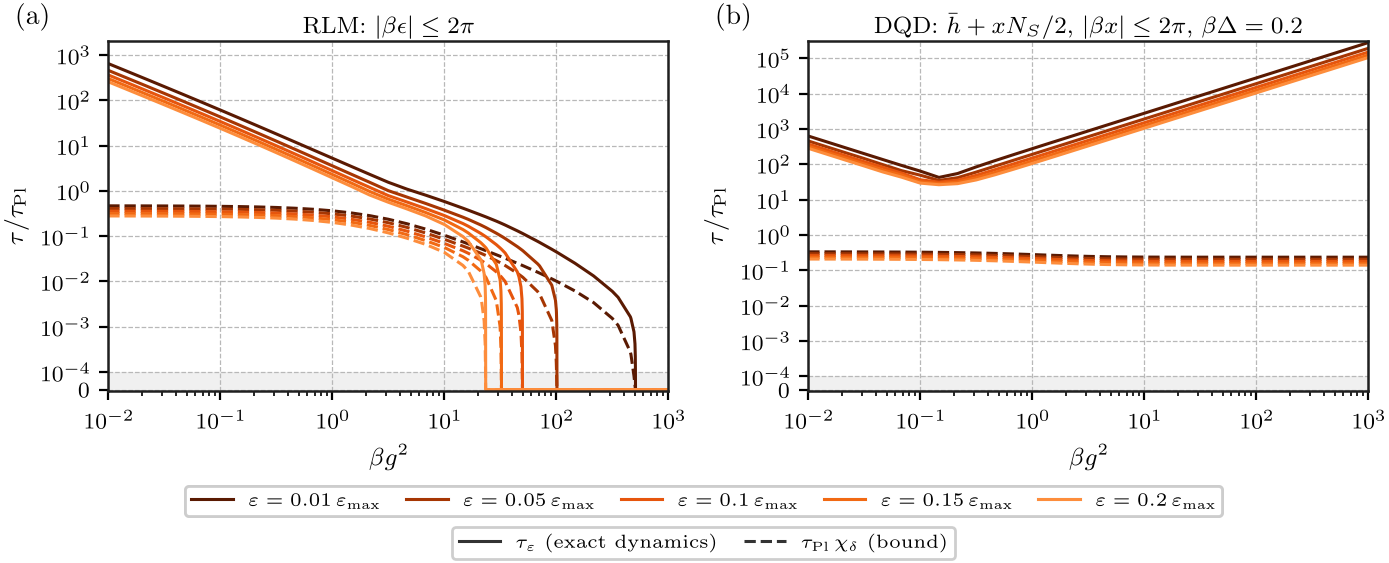

In [6]:
def series(family, eps_fraction, key):
    rr = sort_by(select(S, family=family, eps_fraction=eps_fraction), 'gamma')
    return column(rr, 'gamma', key)


TAU, BOUND = dict(ls='-'), dict(ls='--')


def eps_sweep(ax, fam):
    """tau_eps (solid) and the bound (dashed) for the five accuracies, one colour each."""
    for e, c in EPS_COLOR.items():
        ax.plot(*series(fam, e, 'tau'), color=c, lw=LWD, **TAU)
        ax.plot(*series(fam, e, 'chi'), color=c, lw=LWD, **BOUND)


def style_handles(color='0.2'):
    return [Line2D([], [], color=color, lw=LWD, **TAU, label=r'$\tau_\varepsilon$ (exact dynamics)'),
            Line2D([], [], color=color, lw=LWD, **BOUND, label=r'$\tau_{\rm Pl}\,\chi_\delta$ (bound)')]


fig, ax = figure('row2', legend_rows=1.65)
for a, fam, top in [(ax[0], 'rlm', 2e3), (ax[1], 'dqd_common', 3e5)]:
    eps_sweep(a, fam)
    symlog(a, 1e-4, top)
    a.set(xlabel=r'$\beta g^2$', ylabel=r'$\tau/\tau_{\rm Pl}$'); grid(a)
title(ax[0], '(a)', r'RLM: $|\beta\epsilon|\leq 2\pi$')
title(ax[1], '(b)', r'DQD: $\bar h+x N_S/2$, $|\beta x|\leq 2\pi$, $\beta\Delta=0.2$')
l1 = shared_legend(fig, [Line2D([], [], color=c, lw=LWD, label=eps_label(e))
                         for e, c in EPS_COLOR.items()], ncol=5, y=0.235)
fig.add_artist(l1)
shared_legend(fig, style_handles(), ncol=2, y=0.02)
save(fig, 'fermionic_finite_error');

The two panels are the two regimes of the criterion of Sec. III.

**RLM (a).** Both the bound and the true time fall to exactly zero at the *same* finite
coupling, and the paper derives why. The targets are diagonal, so their Bures angle is
$D(\tilde\omega_x,\tilde\omega_y)=|\theta_x-\theta_y|$ with
$\theta_x=\arcsin\sqrt{p_{\rm th}(x)}$ monotonic in $x$. Particle–hole symmetry gives
$\theta_{-x}=\pi/2-\theta_x$, so the preparation $p(0)=1/2$, i.e. $\theta=\pi/4$, is the
geodesic midpoint of the extreme targets and
$\max_{|x|\leq\delta}D(\rho_S(0),\tilde\omega_x)=\tfrac12 D(\tilde\omega_{-\delta},\tilde\omega_\delta)$.
Every member therefore starts within $\varepsilon$ of its target exactly when
$D(\tilde\omega_{-\delta},\tilde\omega_\delta)\leq2\varepsilon$, which is also the condition for
$\chi_\delta=0$. Both statements can be checked against the stored data:

In [7]:
theta = lambda x, g2: np.arcsin(np.sqrt(np.clip(p_rlm(x, g2), 0, 1)))
xs = np.linspace(0, cfg['delta'], 9)
for g2 in (0.1, 10.0, 500.0):
    print(f'beta g^2 = {g2:6g}:  max |theta(-x) - (pi/2 - theta(x))| = '
          f'{np.abs(theta(-xs, g2) - (np.pi / 2 - theta(xs, g2))).max():.2e}')

print()
d = cfg['delta']
for e in (0.01, 0.05, 0.1, 0.15, 0.2):
    g2, t = series('rlm', e, 'tau')
    _, c = series('rlm', e, 'chi')
    first_zero = g2[t <= 0][0] if (t <= 0).any() else np.nan
    # the threshold predicted by D(w_-delta, w_delta) = 2 eps
    gc = brentq(lambda g: 2 * theta(-d, g) - np.pi / 2 - 2 * e * pk.EPS_MAX, 1e-3, 1e7)
    print(f'eps = {e:4g} eps_max :  predicted threshold beta g^2_c = {gc:8.2f};  first grid point with '
          f'tau_eps = 0 at {first_zero:8.2f}   (tau_eps and chi_delta vanish on the same rows: '
          f'{np.array_equal(t <= 0, c <= 0)})')

beta g^2 =    0.1:  max |theta(-x) - (pi/2 - theta(x))| = 6.66e-16
beta g^2 =     10:  max |theta(-x) - (pi/2 - theta(x))| = 2.22e-16
beta g^2 =    500:  max |theta(-x) - (pi/2 - theta(x))| = 2.22e-16

eps = 0.01 eps_max :  predicted threshold beta g^2_c =   509.19;  first grid point with tau_eps = 0 at   509.70   (tau_eps and chi_delta vanish on the same rows: True)
eps = 0.05 eps_max :  predicted threshold beta g^2_c =   101.32;  first grid point with tau_eps = 0 at   101.42   (tau_eps and chi_delta vanish on the same rows: True)
eps =  0.1 eps_max :  predicted threshold beta g^2_c =    49.86;  first grid point with tau_eps = 0 at    49.91   (tau_eps and chi_delta vanish on the same rows: True)
eps = 0.15 eps_max :  predicted threshold beta g^2_c =    32.37;  first grid point with tau_eps = 0 at    32.41   (tau_eps and chi_delta vanish on the same rows: True)
eps =  0.2 eps_max :  predicted threshold beta g^2_c =    23.40;  first grid point with tau_eps = 0 at    23.42   (tau_eps and

The threshold $g_c^2$ grows linearly with $\delta$ at strong coupling, so widening the family
only postpones it. The locally exact bound, by contrast, never vanishes: it approaches
$\tau\geq4\hbar/(\pi g^2)$, below the Planckian scale but scaling with the coupling like the
relaxation time.

**DQD (b).** The bound stays finite at every coupling, between 0.20 and 0.29, while
$\tau_\varepsilon$ is nonmonotonic: it falls as $\hbar/g^2$ at weak coupling, is shortest near
$g^2\simeq|\Delta|$ where the two eigenvalues of $\Gamma$ coalesce, and then grows linearly with
$g^2$ as the dark mode relaxes on $2\hbar g^2/\Delta^2$. The equilibrium information that the
RLM loses survives here, because the dark mode keeps a thermal occupation even when the bright
one is pinned. Since the common shift adds a multiple of the identity to $h$ and $\Gamma$, it
shifts both levels without changing the normal modes or their widths, so this coupling
dependence is that of $\bar H_S$ at every accuracy.

## 5. The dark-mode family (Fig. S1 of Appendix B)

Perturbing along $\hat\kappa=n_-$ instead of $N_S/2$ makes the protection explicit. Panel (a) is
the same sweep for the dark family; panel (b) compares the two at
$\varepsilon=0.05\,\varepsilon_{\max}$ together with the slowest relaxation of the family. The
eigenvalues of the drift matrix $\Gamma$ of Eq. (28) are

$$\lambda_\pm(x)=-\frac{i\bar\epsilon}{\hbar}-\frac{g^2}{2\hbar}
  \pm\frac{\sqrt{g^4-\Delta^2}}{2\hbar},$$

which for $g^2\gg|\Delta|$ separate into a fast rate $\Gamma_{\rm fast}=g^2/\hbar$ and a slow
rate $\Gamma_{\rm slow}=\Delta^2/(4\hbar g^2)$. Those are *amplitude* rates: the correlation
matrix decays as $D(t)C(0)D(t)^\dagger$ with $D(t)=e^{\Gamma t}$, so occupations decay twice as
fast, and the dark occupation relaxes on the time scale $2\hbar g^2/\Delta^2$ quoted in the
text — which *grows* with the coupling.

The dotted curves below are that occupation time, maximized over the family,
$\max_{|x|\leq\delta}\bigl[2|\mathrm{Re}\,\lambda_+(x)|\bigr]^{-1}$, which is what the
`slowest_rate` column stores. (The caption of Fig. S1 calls it $1/\Gamma_{\rm slow}$; with the
definition of $\Gamma_{\rm slow}$ given above that name is a factor 2 larger than the quantity
plotted.) The cell after the figure checks the identification against the closed form.

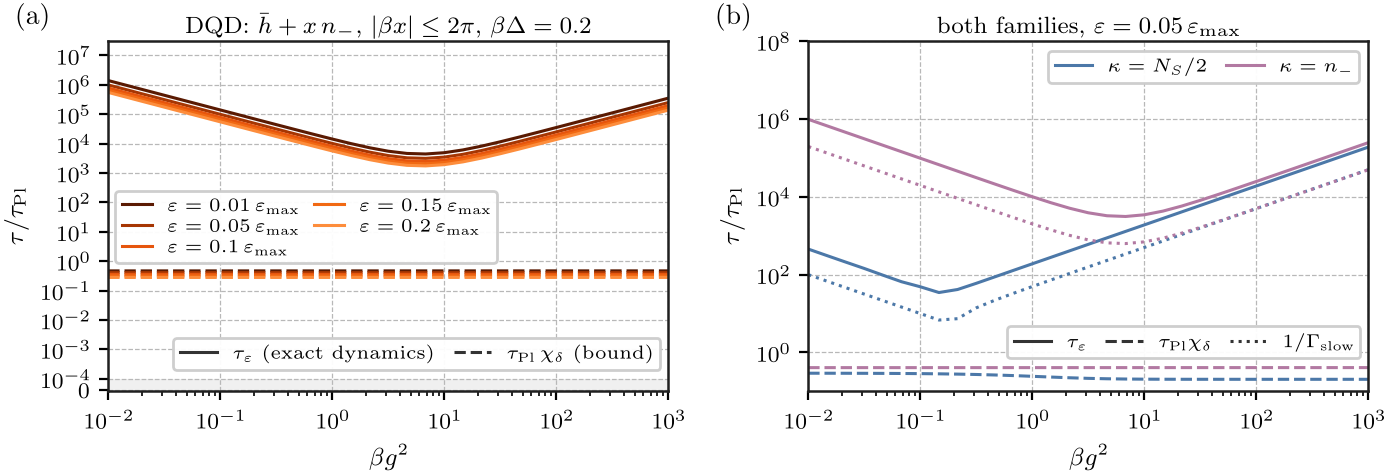

In [8]:
FAMILY = {'dqd_common': (OP_COLOR['common_shift'], r'$\kappa=N_S/2$'),
          'dqd_dark': (OP_COLOR['dark'], r'$\kappa=n_-$')}
EPS_COMPARE = .05

fig, ax = figure('row2')
a = ax[0]
eps_sweep(a, 'dqd_dark')
symlog(a, 1e-4, 3e7)
a.set(xlabel=r'$\beta g^2$', ylabel=r'$\tau/\tau_{\rm Pl}$'); grid(a)
title(a, '(a)', r'DQD: $\bar h+x\,n_-$, $|\beta x|\leq2\pi$, $\beta\Delta=0.2$')
l1 = a.legend(handles=[Line2D([], [], color=c, lw=LWD, label=eps_label(e)) for e, c in EPS_COLOR.items()],
              loc='lower left', bbox_to_anchor=(1.15e-2, 0.9), bbox_transform=a.transData, ncol=2,
              columnspacing=0.8, borderaxespad=0, **{**ps.LEG, 'labelspacing': 0.2})
a.add_artist(l1)
a.legend(handles=style_handles(), loc='lower right', bbox_to_anchor=(8.5e2, 2e-4),
         bbox_transform=a.transData, ncol=2, columnspacing=1.0, borderaxespad=0,
         **{**ps.LEG, 'handlelength': 2.0})

a = ax[1]
for fam, (c, lab) in FAMILY.items():
    g2, t = series(fam, EPS_COMPARE, 'tau')
    _, b = series(fam, EPS_COMPARE, 'chi')
    _, rate = series(fam, EPS_COMPARE, 'slowest_rate')
    a.plot(g2, t, color=c, lw=LWD, **TAU, label=lab)
    a.plot(g2, b, color=c, lw=LWD, **BOUND)
    a.plot(g2, 1 / rate, color=c, lw=LWD, ls=':')
a.set(xscale='log', yscale='log', xlim=XLIM, ylim=(1e-1, 1e8),
      xlabel=r'$\beta g^2$', ylabel=r'$\tau/\tau_{\rm Pl}$'); grid(a)
l1 = a.legend(loc='upper right', ncol=2, columnspacing=1.0, **{**ps.LEG, 'handlelength': 2.0})
a.add_artist(l1)
a.legend(handles=[Line2D([], [], color='0.2', lw=LWD, **TAU, label=r'$\tau_\varepsilon$'),
                  Line2D([], [], color='0.2', lw=LWD, **BOUND, label=r'$\tau_{\rm Pl}\chi_\delta$'),
                  Line2D([], [], color='0.2', lw=LWD, ls=':', label=r'$1/\Gamma_{\rm slow}$')],
         loc='lower right', bbox_to_anchor=(8.5e2, 0.7), bbox_transform=a.transData,
         borderaxespad=0, ncol=3, columnspacing=1.0, **{**ps.LEG, 'handlelength': 2.0})
title(a, '(b)', fr'both families, $\varepsilon={EPS_COMPARE:g}\,\varepsilon_{{\max}}$')
save(fig, 'fermionic_dark_comparison');

The dotted curves show that $\tau_\varepsilon$ follows the slowest occupation relaxation on both
lines, and that on the dark line that rate is suppressed by the detuning. The gain of the dark
perturbation over the common shift in the *bound* is more modest but systematic, and at strong
coupling it is exactly the factor 2 of Eq. (34).

In [9]:
_, chi_dark = series('dqd_dark', EPS_COMPARE, 'chi')
g2, chi_common = series('dqd_common', EPS_COMPARE, 'chi')
for i in (0, len(g2) // 2, -1):
    print(f'beta g^2 = {g2[i]:8.2f}:  chi_dark/chi_common = {chi_dark[i] / chi_common[i]:.2f}'
          f'   (chi_dark = {chi_dark[i]:.3f})')

# locally exact dark-mode bound at strong coupling, Eq. (34)
f = 1 / (1 + np.exp(1.1))
print(f'\nEq. (34):  sqrt(f(1-f)) with f = f_beta(1.1) = {np.sqrt(f * (1 - f)):.5f}')
rr = sort_by(select(R, model='dqd', mean=1.1, direction='dark'), 'gamma')
print(f'           chi_tilde(n_-) at beta g^2 = {rr[-1]["gamma"]:g} is {rr[-1]["chi_tilde"]:.5f}')

# the dotted curve against the closed-form rates, Delta = 0.2
D2 = 0.2 ** 2
print('\nslowest_rate vs the closed form, strong coupling:')
for fam in ('dqd_common', 'dqd_dark'):
    g2s, rate = series(fam, EPS_COMPARE, 'slowest_rate')
    for gg in (100.0, 1000.0):
        k = int(np.argmin(np.abs(g2s - gg)))
        print(f'  {fam:11s} beta g^2 = {g2s[k]:7g}:  stored {rate[k]:.4e}   '
              f'2|Re lambda_+| = Delta^2/(2 g^2) = {D2 / (2 * g2s[k]):.4e}   '
              f'(Gamma_slow = Delta^2/(4 g^2) = {D2 / (4 * g2s[k]):.4e})')

beta g^2 =     0.01:  chi_dark/chi_common = 1.39   (chi_dark = 0.407)
beta g^2 =     3.16:  chi_dark/chi_common = 1.89   (chi_dark = 0.407)
beta g^2 =  1000.00:  chi_dark/chi_common = 2.00   (chi_dark = 0.408)

Eq. (34):  sqrt(f(1-f)) with f = f_beta(1.1) = 0.43286
           chi_tilde(n_-) at beta g^2 = 1000 is 0.43286

slowest_rate vs the closed form, strong coupling:
  dqd_common  beta g^2 =     100:  stored 2.0000e-04   2|Re lambda_+| = Delta^2/(2 g^2) = 2.0000e-04   (Gamma_slow = Delta^2/(4 g^2) = 1.0000e-04)
  dqd_common  beta g^2 =    1000:  stored 2.0000e-05   2|Re lambda_+| = Delta^2/(2 g^2) = 2.0000e-05   (Gamma_slow = Delta^2/(4 g^2) = 1.0000e-05)
  dqd_dark    beta g^2 =     100:  stored 1.9921e-04   2|Re lambda_+| = Delta^2/(2 g^2) = 2.0000e-04   (Gamma_slow = Delta^2/(4 g^2) = 1.0000e-04)
  dqd_dark    beta g^2 =    1000:  stored 1.9999e-05   2|Re lambda_+| = Delta^2/(2 g^2) = 2.0000e-05   (Gamma_slow = Delta^2/(4 g^2) = 1.0000e-05)


## 6. Benchmark against open-system speed limits (Fig. S2 of Appendix B)

The natural alternative bound is a quantum speed limit. The rate at which $\rho_S(t)$ moves in
Bures angle is at most $\sqrt{\mathcal F^S(t)}/2$, and for a system coupled to an arbitrary
environment $\hbar\sqrt{\mathcal F^S}/2$ is bounded by the standard deviation $\delta E_S$ of
$H_S+V$ in the global state, which in turn is at most $\|H_S+V\|/2$. With
$\mathcal D(H_S)=[D(\rho_S(0),\tilde\omega)-\varepsilon]_+$ the Bures angle each member must
travel, this gives the chain [Eq. (11)]

$$\frac{2\hbar\,\mathcal D}{\|H_S+V\|}\;\leq\;
  \frac{\hbar\,\mathcal D}{\langle\delta E_S\rangle_{\tau_\varepsilon}}\;\leq\;
  \frac{2\,\mathcal D}{\bigl\langle\sqrt{\mathcal F^S}\bigr\rangle_{\tau_\varepsilon}}\;\leq\;
  \tau_\varepsilon,$$

whose middle term, maximized over the family, is the Shiraishi–Saito (SS) bound [Eq. (12)]. The
three forms get tighter as they use more of the process: the first needs only the operator
$H_S+V$, the second the energy fluctuations along the global trajectory, the third the full
reduced trajectory — which already determines $\tau_\varepsilon$ itself.

Speed limits bound the *preparation* cost, ours the *information* cost, and the larger of the
two applies. In these models the exact dynamics is available, so both can be evaluated for the
same task, which favours the speed limit: it uses the energy fluctuations along the exact
trajectories, while our bound uses only the equilibrium targets. The outcome is nevertheless
dictated by the bandwidth. The reservoir acts through a single collective mode, so in the
factorized initial state

$$\mathrm{Var}(V)=\frac{N g^2\Lambda}{4},\qquad \|H_S+V\|\simeq g\sqrt{2N\Lambda},$$

and once these dominate, both forms fall as $(g^2\Lambda)^{-1/2}$ — a dependence on an
ultraviolet scale that leaves the MFG targets, and the dynamics at $t\gg\hbar/\Lambda$,
essentially unchanged. `benchmark.csv` evaluates everything in the same Lorentzian model at
$\Lambda/k_BT=10^2,\dots,10^8$.

In [10]:
B = read_csv(DATA / 'speedlimits' / 'benchmark.csv')
bcfg = json.loads((DATA / 'speedlimits' / 'config.json').read_text())
widths = sorted({r['width'] for r in B})
print('bandwidths Lambda/k_BT:', [f'{w:g}' for w in widths])

tau, ss_var, ss_sta, chi = column(B, 'tau', 'ss_variance', 'ss_static', 'chi')
ok = tau > 0
print(f'\nthe chain of Eq. (11), on all {len(B)} rows:')
print(f'  violations of tau_SS(static) <= tau_SS(variance) : {int((ss_sta > ss_var + 1e-9).sum())}')
print(f'  violations of tau_SS(variance) <= tau_eps        : {int((ss_var[ok] > tau[ok] + 1e-9).sum())}')
print(f'  violations of tau_Pl chi_delta <= tau_eps        : {int((chi[ok] > tau[ok] + 1e-9).sum())}')

# the two closed forms quoted above, in the deep wide band
print('\nVar(V) = N g^2 Lambda/4 and ||H_S+V|| = g sqrt(2 N Lambda), tested at Lambda = 1e8:')
for fam, N in (('rlm', 1), ('dqd', 2)):
    rr = sort_by(select(B, family=fam, width=1e8, eps_fraction=0.05), 'gamma')
    g2, num, ssv, sss = column(rr, 'gamma', 'max_numerator', 'ss_variance', 'ss_static')
    k = (num > 0) & (ssv > 0)
    pv = num[k] / np.sqrt(N * g2[k] * 1e8 / 4)                 # hbar D / sqrt(Var(V))
    ps = 2 * num[k] / (np.sqrt(g2[k]) * np.sqrt(2 * N * 1e8))  # 2 hbar D / ||H_S+V||
    print(f'  {fam.upper():4s} (N={N}):  variance form to {np.abs(ssv[k] / pv - 1).max():.1e},'
          f'  static form to {np.abs(sss[k] / ps - 1).max():.1e},'
          f'  static/variance = {np.median(sss[k] / ssv[k]):.5f} (1/sqrt2 = {1 / np.sqrt(2):.5f})')

bandwidths Lambda/k_BT: ['100', '1000', '10000', '100000', '1e+06', '1e+08']

the chain of Eq. (11), on all 2440 rows:
  violations of tau_SS(static) <= tau_SS(variance) : 0
  violations of tau_SS(variance) <= tau_eps        : 0
  violations of tau_Pl chi_delta <= tau_eps        : 0

Var(V) = N g^2 Lambda/4 and ||H_S+V|| = g sqrt(2 N Lambda), tested at Lambda = 1e8:
  RLM  (N=1):  variance form to 1.6e-05,  static form to 9.9e-06,  static/variance = 0.70710 (1/sqrt2 = 0.70711)
  DQD  (N=2):  variance form to 2.7e-04,  static form to 2.1e-03,  static/variance = 0.70698 (1/sqrt2 = 0.70711)


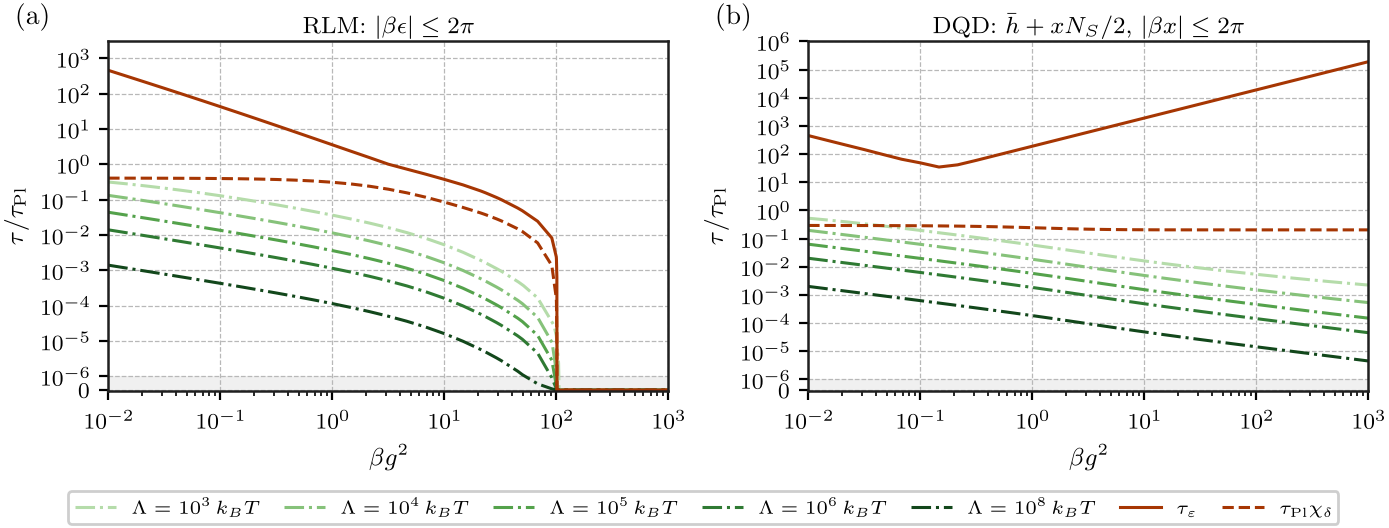

In [11]:
EPS_SENS = .05
SENS_WIDTHS = [1e3, 1e4, 1e5, 1e6, 1e8]


def lam_label(W):
    return rf'$\Lambda=10^{{{int(round(np.log10(W)))}}}\,k_BT$'


def bseries(fam, W, eps_fraction, key):
    rr = sort_by(select(B, family=fam, width=W, eps_fraction=eps_fraction), 'gamma')
    return column(rr, 'gamma', key)


TOP = {'rlm': 3e3, 'dqd': 1e6}
Wmax = max(widths)
fig, ax = figure('row2', legend_rows=1)
ce = EPS_COLOR[EPS_SENS]
for a, fam in [(ax[0], 'rlm'), (ax[1], 'dqd')]:
    for W in SENS_WIDTHS:
        a.plot(*bseries(fam, W, EPS_SENS, 'ss_variance'), color=LAMBDA_COLOR[W], lw=LWD, ls='-.')
    a.plot(*bseries(fam, Wmax, EPS_SENS, 'tau'), color=ce, lw=LWD)
    a.plot(*bseries(fam, Wmax, EPS_SENS, 'chi'), color=ce, lw=LWD, ls='--')
    symlog(a, 1e-6, TOP[fam])
    a.set(xlabel=r'$\beta g^2$', ylabel=r'$\tau/\tau_{\rm Pl}$'); grid(a)
title(ax[0], '(a)', r'RLM: $|\beta\epsilon|\leq2\pi$')
title(ax[1], '(b)', r'DQD: $\bar h+xN_S/2$, $|\beta x|\leq2\pi$')
h = [Line2D([], [], color=LAMBDA_COLOR[W], lw=LWD, ls='-.', label=lam_label(W)) for W in SENS_WIDTHS]
h += [Line2D([], [], color=ce, lw=LWD, label=r'$\tau_\varepsilon$'),
      Line2D([], [], color=ce, lw=LWD, ls='--', label=r'$\tau_{\rm Pl}\chi_\delta$')]
shared_legend(fig, h, ncol=7)
save(fig, 'speedlimit_sensitivity');

$\Lambda=10^2\,k_BT$ is left out of the figure: it is outside the wide-band regime at every
coupling shown (the validity flag `wb_regime` in `benchmark.csv` marks this), so its curves
describe a different physical model rather than a different approximation of the same one. Its
rows are kept in the data file.

The conclusion of the appendix is the separation of the two bounds: in the wide band our bound
is essentially $\Lambda$-independent while $\tau_{\rm SS}$ falls off as
$(g^2\Lambda)^{-1/2}$, so SS becomes uninformative exactly in the strong-coupling,
wide-band regime where the equilibrium argument still has content. The one place where
$\chi_\delta$ does move with $\Lambda$ is the immediate neighbourhood of the RLM threshold,
where it is already near zero and a slight shift of the threshold is a large *relative* change;
the comparison below therefore excludes those points.

In [12]:
for fam in ('rlm', 'dqd'):
    g2, c8 = bseries(fam, Wmax, EPS_SENS, 'chi')
    _, c4 = bseries(fam, 1e4, EPS_SENS, 'chi')
    _, s8 = bseries(fam, Wmax, EPS_SENS, 'ss_variance')
    _, s4 = bseries(fam, 1e4, EPS_SENS, 'ss_variance')
    k = c8 > 1e-3                      # away from the RLM threshold, where chi_delta itself is 0
    print(f'{fam.upper():4s}: max |chi(1e4)/chi(1e8) - 1| = {np.max(np.abs(c4[k] / c8[k] - 1)):.1e}'
          f'   (over the {k.sum()} of {len(g2)} couplings with chi_delta > 1e-3)')
    k = (s8 > 0) & (s4 > 0)
    print(f'      median tau_SS(1e4)/tau_SS(1e8) = {np.median(s4[k] / s8[k]):.1f}'
          f'   (expected sqrt(1e8/1e4) = {np.sqrt(1e4):.0f})')

RLM : max |chi(1e4)/chi(1e8) - 1| = 1.0e-02   (over the 37 of 51 couplings with chi_delta > 1e-3)
      median tau_SS(1e4)/tau_SS(1e8) = 100.5   (expected sqrt(1e8/1e4) = 100)
DQD : max |chi(1e4)/chi(1e8) - 1| = 5.2e-05   (over the 31 of 31 couplings with chi_delta > 1e-3)
      median tau_SS(1e4)/tau_SS(1e8) = 100.5   (expected sqrt(1e8/1e4) = 100)


## 7. Recomputing the data

Everything read above is produced by three scripts, all of which import the same exact solver in
`src/fermionic/engine/` and write into `data/fermionic/`:

| script | output | cost |
|---|---|---|
| `src/fermionic/local_sensitivity/local_sensitivity.py` | `local_sensitivity.csv`, `checks.json` (Fig. 1) | ~1 min |
| `src/fermionic/local_sensitivity/ss_bandwidth_table.py` | `ss_bandwidth_table.csv/.json` | ~1 min |
| `src/fermionic/families/compute.py` | `sweep.csv`, `checks.json`, `config.json` (Figs. 2, S1) | ~10 min, 8 processes |
| `src/fermionic/speedlimits/compute.py` | `benchmark.csv`, `checks.json`, `config.json` (Fig. S2) | ~10 min, 8 processes |

`ss_bandwidth_table.csv` tabulates $\tau_\varepsilon$, the bound and the two speed limits
against $\Lambda$. An earlier version of the manuscript printed it as a table; the current one
makes the same point with Fig. S2, so the file is shipped as data without a corresponding table.

Run them from the repository root, e.g. `python src/fermionic/families/compute.py`. Each writes
a `checks.json` next to its data with the validation it performed; the main entries are
reproduced below.

In [13]:
for name in ('local_sensitivity', 'families', 'speedlimits'):
    checks = json.loads((DATA / name / 'checks.json').read_text())
    print(f'--- {name}/checks.json ---')
    print(json.dumps(checks, indent=1)[:900].rstrip(), '\n')

--- local_sensitivity/checks.json ---
{
 "finite_difference_relative_change": 3.7433880615332e-12,
 "rlm_occupation_readout_saturates": 2.9029078371658355e-10,
 "convexity_common_shift_le_optimum": true,
 "optimum_ge_all_directions": true,
 "response_le_qfi": true,
 "strong_coupling_mean1.1": {
  "q": 0.18736987954752055,
  "chi_dark": 0.43286028294515455,
  "chi_dark_limit": 0.43286242565914695,
  "chi_common": 0.21643037348251007,
  "chi_common_limit": 0.21643121282957348,
  "chi_opt": 0.43286028473910243,
  "dark_weight_opt": 0.9999999965828916
 },
 "strong_coupling_mean2.35": {
  "q": 0.07948532370965024,
  "chi_dark": 0.28193010181144895,
  "chi_dark_limit": 0.2819314166772661,
  "chi_common": 0.1409654089884002,
  "chi_common_limit": 0.14096570833863306,
  "chi_opt": 0.28193010995560774,
  "dark_weight_opt": 0.9999999717856842
 },
 "units": "hbar=beta=1, gamma=g^2, wide-band MFG",
 "script_hash": "add93b05dddfc5cc1dc42 

--- families/checks.json ---
{
 "bound_le_tau_violations": 